# Experiment 1: priming / persona → KV change

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from kvmeaning.store import load

RUN = sorted(Path('../runs').iterdir())[-1]
FIG = Path('../figures/exp1')
FIG.mkdir(parents=True, exist_ok=True)
REPS = ('v', 'k_pre', 'k_post', 'resid')
KV = REPS[:3]
CONDS = ('F1', 'F2', 'H+', 'H-', 'P1', 'P2')
EFFECT = ('H+', 'H-', 'P1', 'P2')
PIDS = sorted(p.name for p in (RUN / 'exp1').iterdir())

# Bodies differ in length across passages; truncating to the shortest keeps position-wise stacking valid.
SPANS = {pid: load(RUN / 'exp1' / pid / 'F1')[1]['spans']['body'] for pid in PIDS}
TB = min(b - a for a, b in SPANS.values())

D, LOGITS = {}, {}
for pid in PIDS:
    for c in CONDS:
        t, m = load(RUN / 'exp1' / pid / c)
        a, _ = m['spans']['body']
        b = a + TB
        D[pid, c] = {r: (t[r][:, a:b] if r == 'resid' else t[r][:, :, a:b]) for r in REPS}
        LOGITS[pid, c] = t['logits_last'].float()
NL = D[PIDS[0], 'F1']['v'].shape[0]
print(RUN.name, PIDS, 'layers', NL, 'body tokens', TB)

20261010-110534-0.6B ['p01', 'p02', 'p03', 'p04', 'p05'] layers 28 body tokens 246


In [2]:
def tokdist(x, y, scale):
    x, y = x.float(), y.float()
    return (x - y).norm(dim=-1) / scale, 1 - F.cosine_similarity(x, y, dim=-1)


def scale_of(pid, r):
    # Per-(layer, head) mean norm of the F1 body vectors, so heads with large norms do not dominate.
    return D[pid, 'F1'][r].float().norm(dim=-1).mean(-1, keepdim=True)


PAIRS = [('F1', 'F2')] + [('F1', c) for c in EFFECT] + [('P1', 'P2')]
DIST = {}
for pid in PIDS:
    for r in REPS:
        sc = scale_of(pid, r)
        for a, b in PAIRS:
            DIST[pid, r, a, b] = tokdist(D[pid, a][r], D[pid, b][r], sc)


def mean_over_passages(r, a, b, k):
    return torch.stack([DIST[pid, r, a, b][k] for pid in PIDS]).mean(0)  # [L, (H,) T]


# Layer 0: body-token inputs are identical in every condition, so K/V there depend on the prefix only
# through nothing; resid index 0 is the embedding output.
for r in KV:
    print(r, 'layer-0 max abs diff F1 vs P1:', float(mean_over_passages(r, 'F1', 'P1', 0)[0].max()))

v layer-0 max abs diff F1 vs P1: 0.0
k_pre layer-0 max abs diff F1 vs P1: 0.0
k_post layer-0 max abs diff F1 vs P1: 0.0


## 1. Layer×head heatmap (distance / noise floor)

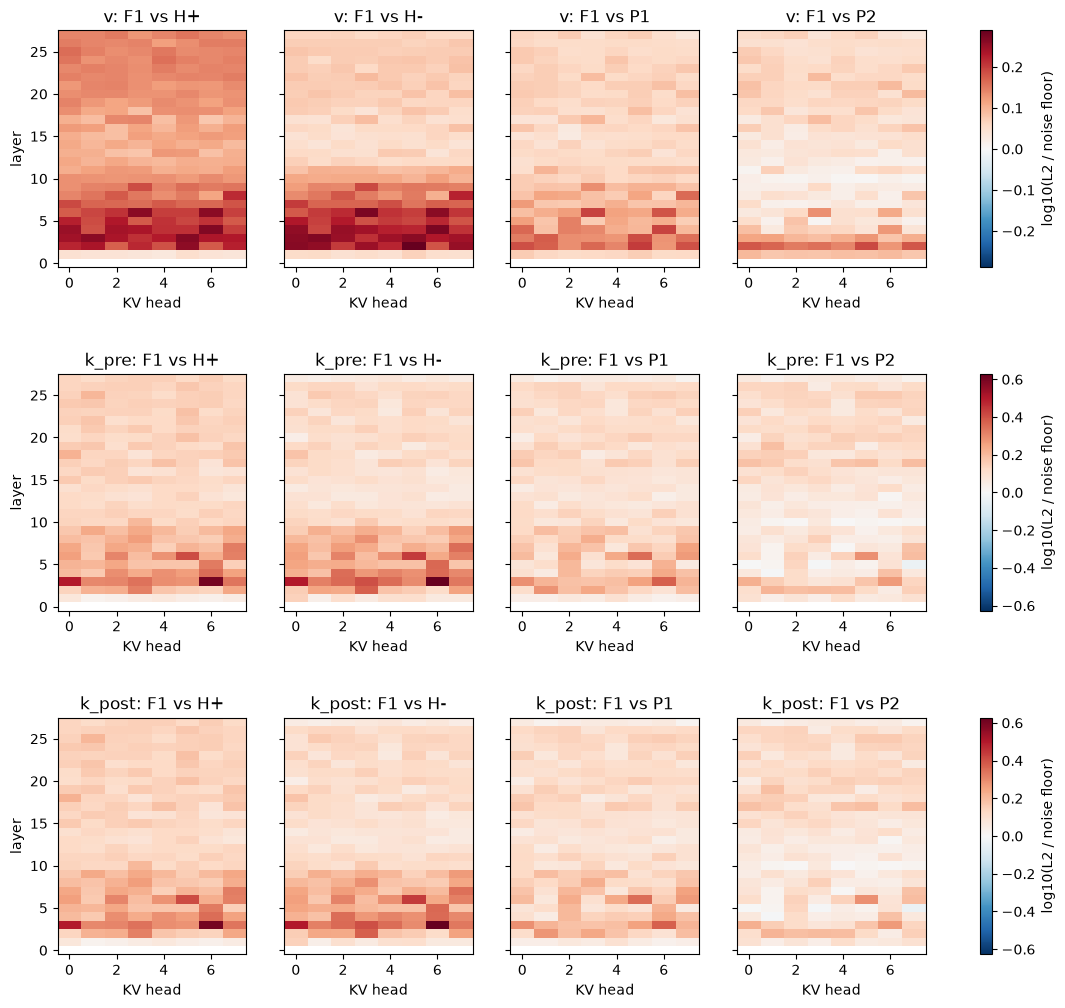

In [3]:
def ratio(eff, floor, eps=1e-6):
    return torch.where(floor > eps, eff / floor.clamp_min(eps), torch.full_like(eff, float('nan')))


fig, axes = plt.subplots(len(KV), len(EFFECT), figsize=(14, 12), sharey=True, gridspec_kw=dict(hspace=0.45))
for i, r in enumerate(KV):
    floor = mean_over_passages(r, 'F1', 'F2', 0).mean(-1)
    ratios = {c: ratio(mean_over_passages(r, 'F1', c, 0).mean(-1), floor) for c in EFFECT}
    lim = max(float(np.nanmax(np.abs(np.log10(v.numpy())))) for v in ratios.values())
    for j, c in enumerate(EFFECT):
        ax = axes[i, j]
        im = ax.imshow(np.log10(ratios[c].numpy()), origin='lower', aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim)
        ax.set_title(f'{r}: F1 vs {c}')
        ax.set_xlabel('KV head')
        if j == 0:
            ax.set_ylabel('layer')
    fig.colorbar(im, ax=axes[i, :], label='log10(L2 / noise floor)')
fig.savefig(FIG / 'heatmap.png', dpi=130, bbox_inches='tight')
plt.show()

## 2. Layer curve

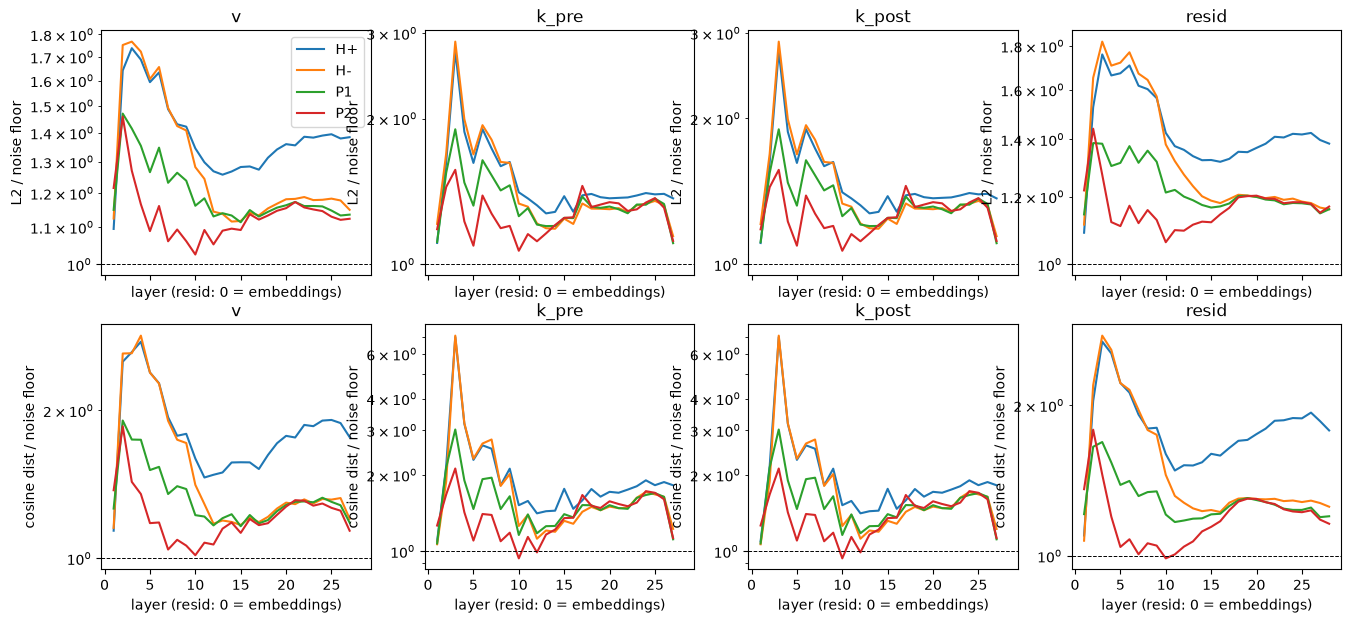

v L2 ratio at last layer: {'H+': 1.38, 'H-': 1.15, 'P1': 1.14, 'P2': 1.12} max over layers: {'H+': 1.74, 'H-': 1.77, 'P1': 1.47, 'P2': 1.46}
k_pre L2 ratio at last layer: {'H+': 1.37, 'H-': 1.14, 'P1': 1.11, 'P2': 1.12} max over layers: {'H+': 2.76, 'H-': 2.88, 'P1': 1.9, 'P2': 1.57}
k_post L2 ratio at last layer: {'H+': 1.37, 'H-': 1.14, 'P1': 1.11, 'P2': 1.12} max over layers: {'H+': 2.75, 'H-': 2.88, 'P1': 1.9, 'P2': 1.57}
resid L2 ratio at last layer: {'H+': 1.38, 'H-': 1.16, 'P1': 1.16, 'P2': 1.17} max over layers: {'H+': 1.76, 'H-': 1.82, 'P1': 1.39, 'P2': 1.44}


In [4]:
fig, axes = plt.subplots(2, len(REPS), figsize=(16, 7), sharex=True)
LAYER_CURVE = {}
for j, r in enumerate(REPS):
    for k, name in enumerate(('L2 / noise floor', 'cosine dist / noise floor')):
        def lc(a, b):
            x = mean_over_passages(r, a, b, k)
            return x.mean(dim=tuple(range(1, x.dim()))) if r == 'resid' else x.mean(dim=(1, 2))
        floor = lc('F1', 'F2')
        ax = axes[k, j]
        for c in EFFECT:
            y = ratio(lc('F1', c), floor)
            LAYER_CURVE[r, k, c] = y
            ax.plot(range(len(y)), y, label=c)
        ax.axhline(1, color='k', lw=0.7, ls='--')
        ax.set_yscale('log')
        ax.set_title(f'{r}')
        ax.set_ylabel(name)
        ax.set_xlabel('layer (resid: 0 = embeddings)')
axes[0, 0].legend()
fig.savefig(FIG / 'layer_curve.png', dpi=130, bbox_inches='tight')
plt.show()
for r in REPS:
    print(r, 'L2 ratio at last layer:', {c: round(float(LAYER_CURVE[r, 0, c][-1]), 2) for c in EFFECT},
          'max over layers:', {c: round(float(np.nanmax(LAYER_CURVE[r, 0, c].numpy())), 2) for c in EFFECT})

## 3. Within-body decay curve

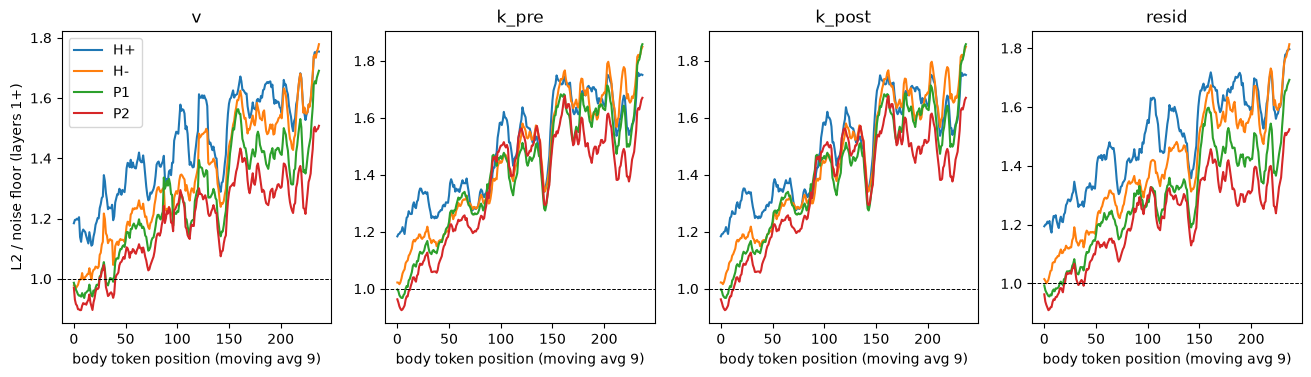

In [5]:
def smooth(y, w=9):
    return np.convolve(y, np.ones(w) / w, mode='valid')


fig, axes = plt.subplots(1, len(REPS), figsize=(16, 3.8), sharey=False)
for j, r in enumerate(REPS):
    def by_pos(a, b):
        x = mean_over_passages(r, a, b, 0)[1:]  # drop layer 0 (identical in all conditions)
        return x.mean(dim=tuple(range(x.dim() - 1))).numpy()
    floor = by_pos('F1', 'F2')
    for c in EFFECT:
        axes[j].plot(smooth(by_pos('F1', c) / floor), label=c)
    axes[j].axhline(1, color='k', lw=0.7, ls='--')
    axes[j].set_title(r)
    axes[j].set_xlabel('body token position (moving avg 9)')
axes[0].set_ylabel('L2 / noise floor (layers 1+)')
axes[0].legend()
fig.savefig(FIG / 'decay.png', dpi=130, bbox_inches='tight')
plt.show()

## 4. Direction vectors and cross-passage cosine

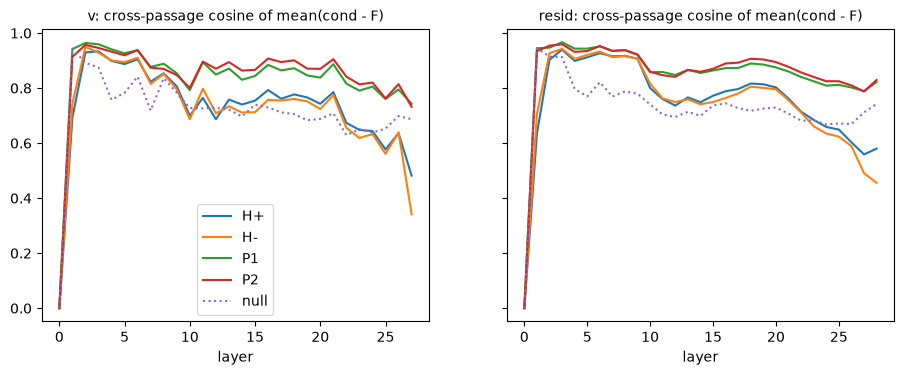

In [6]:
def mean_diff(pid, r, c, ref):
    # per-layer mean over body tokens of (c - ref), flattened over heads: [L, features]
    x = D[pid, c][r].float() - ref(pid, r)
    x = x.transpose(1, 2).flatten(2) if r != 'resid' else x
    return x.mean(dim=-2)


def f_mean(pid, r):
    return 0.5 * (D[pid, 'F1'][r].float() + D[pid, 'F2'][r].float())


DIRS = {}
for r in ('v', 'resid'):
    for c in EFFECT:
        DIRS[r, c] = torch.stack([mean_diff(pid, r, c, f_mean) for pid in PIDS])  # [P, L, F]
    # Null direction: F1 - F2 has no semantic content, so its cross-passage cosine is the chance level.
    DIRS[r, 'null'] = torch.stack([mean_diff(pid, r, 'F1', lambda p, rr: D[p, 'F2'][rr].float()) for pid in PIDS])


def cross_cos(d):
    u = F.normalize(d, dim=-1)
    n = len(PIDS)
    g = torch.einsum('plf,qlf->pql', u, u)
    off = ~torch.eye(n, dtype=torch.bool)
    return g[off].mean(0)  # [L]


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, r in zip(axes, ('v', 'resid')):
    for c in (*EFFECT, 'null'):
        ax.plot(range(DIRS[r, c].shape[1]), cross_cos(DIRS[r, c]), label=c, ls=':' if c == 'null' else '-')
    ax.set_title(f'{r}: cross-passage cosine of mean(cond - F)', fontsize=10)
    ax.set_xlabel('layer')
axes[0].legend()
fig.savefig(FIG / 'direction_cosine.png', dpi=130, bbox_inches='tight')
plt.show()

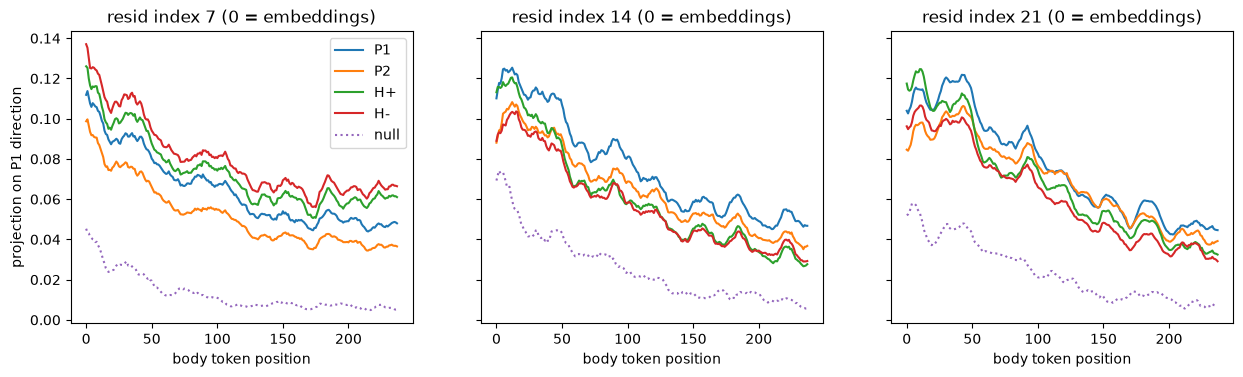

In [7]:
# Per-token projection on the leave-one-passage-out persona direction (resid space, in units of F1 mean norm).
layers_show = [NL // 4, NL // 2, 3 * NL // 4]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, l in zip(axes, layers_show):
    for c in ('P1', 'P2', 'H+', 'H-', 'null'):
        curves = []
        for i, pid in enumerate(PIDS):
            others = [k for k in range(len(PIDS)) if k != i]
            u = F.normalize(DIRS['resid', 'P1'][others, l].mean(0), dim=-1)
            ref = D[pid, 'F2']['resid'][l].float() if c == 'null' else f_mean(pid, 'resid')[l]
            src = D[pid, 'F1' if c == 'null' else c]['resid'][l].float()
            curves.append(((src - ref) @ u) / scale_of(pid, 'resid')[l, 0])
        ax.plot(smooth(torch.stack(curves).mean(0).numpy()), label=c, ls=':' if c == 'null' else '-')
    ax.set_title(f'resid index {l} (0 = embeddings)')
    ax.set_xlabel('body token position')
axes[0].set_ylabel('projection on P1 direction')
axes[0].legend()
fig.savefig(FIG / 'direction_projection.png', dpi=130, bbox_inches='tight')
plt.show()

## 5. Linear probe per layer (passage-level split)

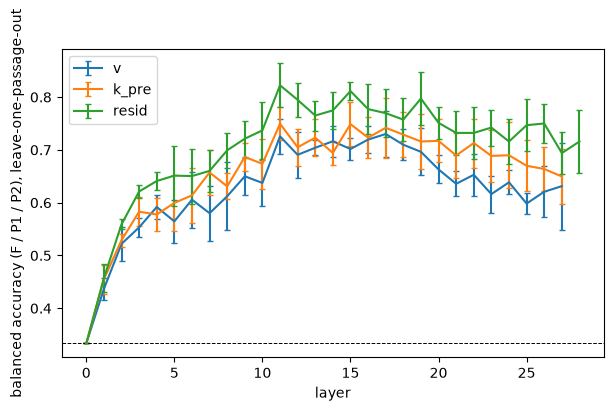

v layer0 acc 0.333 best 0.73 at layer 17
k_pre layer0 acc 0.333 best 0.75 at layer 11
resid layer0 acc 0.333 best 0.822 at layer 11


In [8]:
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LAB = {'F1': 0, 'F2': 0, 'P1': 1, 'P2': 2}
STEP = 3


def feats(pid, c, r, l):
    x = D[pid, c][r][l].float()
    return (x.transpose(0, 1).flatten(1) if r != 'resid' else x)[::STEP].numpy()


def probe_layer(r, l):
    X, y, g = [], [], []
    for pi, pid in enumerate(PIDS):
        for c, lab in LAB.items():
            f = feats(pid, c, r, l)
            X.append(f); y += [lab] * len(f); g += [pi] * len(f)
    X, y, g = np.concatenate(X), np.array(y), np.array(g)
    accs = []
    for held in range(len(PIDS)):
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=300, class_weight='balanced'))
        clf.fit(X[g != held], y[g != held])
        accs.append(balanced_accuracy_score(y[g == held], clf.predict(X[g == held])))
    return float(np.mean(accs)), float(np.std(accs))


PROBE = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for r in ('v', 'k_pre', 'resid'):
        PROBE[r] = np.array([probe_layer(r, l) for l in range(NL + (r == 'resid'))])

fig, ax = plt.subplots(figsize=(7, 4))
for r, a in PROBE.items():
    ax.errorbar(range(len(a)), a[:, 0], yerr=a[:, 1], label=r, capsize=2)
ax.axhline(1 / 3, color='k', ls='--', lw=0.7)
ax.set_xlabel('layer')
ax.set_ylabel('balanced accuracy (F / P1 / P2), leave-one-passage-out')
ax.legend()
fig.savefig(FIG / 'probe.png', dpi=130, bbox_inches='tight')
plt.show()
for r, a in PROBE.items():
    print(r, 'layer0 acc', round(a[0, 0], 3), 'best', round(a[:, 0].max(), 3), 'at layer', int(a[:, 0].argmax()))

## 6. Behavioral link: next-token KL

In [9]:
import json

from kvmeaning import model as M

# Stored logits_last is the assistant-turn start, where <think> has p > 0.999 in every condition, so it
# cannot show any effect. The plan asks for the distribution at body end: re-run the stored ids truncated there
# (causal attention makes the position-(b1-1) logits identical to the full run).
model, tok = M.load('0.6B')
BODY_END = {}
for pid in PIDS:
    for c in CONDS:
        meta = json.loads((RUN / 'exp1' / pid / f'{c}.json').read_text())
        ids = meta['ids'][:meta['spans']['body'][1]]
        with torch.no_grad():
            BODY_END[pid, c] = model(torch.tensor([ids], device=model.device)).logits[0, -1].float().cpu()
top = F.softmax(BODY_END[PIDS[0], 'F1'], -1).topk(3)
print('p01 F1 top-3 next tokens at body end:', [(tok.decode(int(i)), round(float(v), 3)) for v, i in zip(*top)])
print('assistant-turn-start top-1 prob (stored logits_last):', round(float(F.softmax(LOGITS[PIDS[0], 'F1'], -1).max()), 4))

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

p01 F1 top-3 next tokens at body end: [(' The', 0.244), (' \n\n', 0.19), (' What', 0.09)]
assistant-turn-start top-1 prob (stored logits_last): 0.9993


KL(cond || ref) in nats at the last body token
pair            p01      p02      p03      p04      p05     mean
F2 vs F1       0.053    0.039    0.017    0.024    0.038    0.034
H+ vs F1       0.112    0.279    0.092    0.165    0.102    0.150
H- vs F1       0.102    0.166    0.076    0.116    0.132    0.119
P1 vs F1       0.105    0.145    0.079    0.172    0.210    0.142
P2 vs F1       0.106    0.078    0.114    0.060    0.096    0.091
P2 vs P1       0.066    0.070    0.058    0.086    0.157    0.087


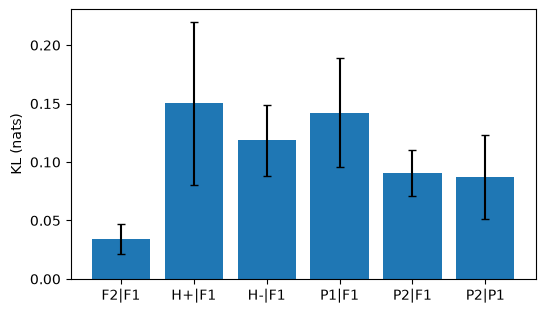

In [10]:
def kl(p_logits, q_logits):
    lp, lq = F.log_softmax(p_logits, -1), F.log_softmax(q_logits, -1)
    return float((lp.exp() * (lp - lq)).sum())


KL_PAIRS = [('F1', c) for c in ('F2', 'H+', 'H-', 'P1', 'P2')] + [('P1', 'P2')]
KL = {(a, b): [kl(BODY_END[pid, b], BODY_END[pid, a]) for pid in PIDS] for a, b in KL_PAIRS}  # KL(b || a)
print('KL(cond || ref) in nats at the last body token')
print(f"{'pair':10s}" + ''.join(f'{p:>9s}' for p in PIDS) + f"{'mean':>9s}")
for (a, b), v in KL.items():
    print(f'{b} vs {a:3s}  ' + ''.join(f'{x:9.3f}' for x in v) + f'{np.mean(v):9.3f}')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([f'{b}|{a}' for a, b in KL_PAIRS], [np.mean(v) for v in KL.values()],
       yerr=[np.std(v) for v in KL.values()], capsize=3)
ax.set_ylabel('KL (nats)')
fig.savefig(FIG / 'kl.png', dpi=130, bbox_inches='tight')
plt.show()

## 7. (Stretch) KV patching

Not run in this pass (scope: analyses 1-6).

## Results summary (Qwen3-0.6B, 5 passages, body truncated to 246 tokens; n is small, treat as pipeline-level evidence)

- **Noise floor / determinism:** re-running a passage gives bit-identical tensors, so the floor is F1-vs-F2 only. Layer 0 K/V are identical across conditions (distance exactly 0), as expected.
- **Effect size (L2 / floor):** every prefix condition is above the floor from layer 1 on, but modest: peak ~1.5-1.8x (V, resid), ~1.6-2.9x (K); ~1.1-1.4x at the last layer. H+/H- peak higher than P1/P2; P2 is closest to the floor. No condition-specific heads stand out in the heatmap; the effect is spread over all 8 KV heads and strongest in layers 1-8.
- **V vs K vs resid:** pre- and post-RoPE K ratios are indistinguishable at this scale (same positions in all conditions, so RoPE cancels). V and resid have similar curves; K shows the sharpest early-layer peak (layer ~3).
- **Decay:** distance / floor *rises* with body position, i.e. the prefix effect does not dilute within 246 tokens relative to the filler floor (the filler difference fades faster than the instruction difference). Raw projections on the P1 direction do decline with position.
- **Direction vectors:** the cross-passage cosine of mean(cond - F) is high (~0.85-0.95 for P1/P2) but the null F1-F2 direction is also ~0.7-0.9, and H+/H-/P2 project onto the P1 direction about as much as P1 does. The shared component looks like a generic "instruction vs filler" offset, not a persona-specific direction.
- **Probe (F / P1 / P2, leave-one-passage-out, chance 0.33):** layer 0 is exactly at chance; accuracy peaks around layers 11-17: resid 0.82, K 0.75, V 0.73. Residual carries the cleanest condition signal; V is lowest.
- **Behavioral link:** at the last prompt token (assistant-turn start) `<think>` has p = 0.9993 in all conditions, so KL there is ~0 and uninformative. At the last body token, KL vs F1 is 0.09-0.15 nats for H+/H-/P1/P2 against 0.034 for F2 (floor), so KV differences do reach the output at ~3-4x the floor.
- **Not run:** analysis 7 (KV patching); 4B model; the 30-50 passage scale.
